In [13]:
# Imports
from langgraph.graph import StateGraph,START,END
from typing import TypedDict , Literal

In [14]:
class ModerationState(TypedDict):
    post_content: str
    user_reputation: str
    formatted_post: str
    content_flag: str
    result: str

In [31]:
def format_post(state: ModerationState):
    # Format the post content
    formatted=f"{state['user_reputation']} says: {state['post_content']}"  
    return {'formatted_post': formatted}

def analyse_content(state: ModerationState):
    content = state['post_content'].lower()
    # Analyze the content for moderation
    if "spam" in content or "buy now" in content:
        flag="rejected"
    elif state['user_reputation'] == "new_user":
        flag="review"
    else:
        flag="approved"
    return {'content_flag': flag}

def approve_post(state: ModerationState):
    # Approve the post
    result="Post approved and published successfully."
    return {'result': result}

def flag_for_review(state: ModerationState):
    # Flag the post for review
    result="Post flagged for review by moderators."
    return {'result': result}

def reject_post(state: ModerationState):
    # Reject the post
    result="Post rejected due to inappropriate content."
    return {'result': result}

def check_condition(state: ModerationState) -> Literal["approve_post", "flag_for_review", "reject_post"]:
    if state['content_flag'] == "approved":
        return "approve_post"       
    elif state['content_flag'] == "review":
        return "flag_for_review"
    else:
        return "reject_post"    
    
    


In [33]:
graph = StateGraph(ModerationState)
# add_node to the graph
graph.add_node("format_post", format_post)
graph.add_node("analyse_content", analyse_content)
graph.add_node("approve_post", approve_post)
graph.add_node("flag_for_review", flag_for_review)
graph.add_node("reject_post", reject_post)


In [34]:
#add edges to the graph
graph.add_edge(START, "format_post")
graph.add_edge("format_post", "analyse_content")

# add conditional edges i.e. particular node will be executed based on the output of the previous node
graph.add_conditional_edges("analyse_content", check_condition)

#connect the end node to all possible outcomes
graph.add_edge("approve_post", END)
graph.add_edge("flag_for_review", END)
graph.add_edge("reject_post", END)

workflow=graph.compile()


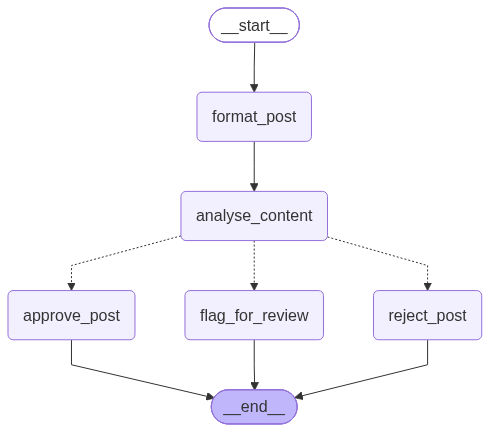

In [35]:
workflow

In [42]:
initial_state = {
    'post_content': "This is a sample post content. Buy Now",  
    'user_reputation': "new_user"
}

workflow.invoke(initial_state)

{'post_content': 'This is a sample post content. Buy Now',
 'user_reputation': 'new_user',
 'formatted_post': 'new_user says: This is a sample post content. Buy Now',
 'content_flag': 'rejected',
 'result': 'Post rejected due to inappropriate content.'}